# EDA — Dataset de Modelagem (Fase 3)

Análise exploratória do dataset nível-aluno montado por
`src/preprocessing/dataset.py` a partir da camada Gold da Fase 2: 1 linha
por aluno de 2024 com prova válida, features territoriais/socioeconômicas
defasadas em 1 ano (sem vazamento) + o alvo `alfabetizado`.

Objetivo: entender distribuição do alvo, relação com as features
disponíveis e formular hipóteses antes de modelar — exatamente a ordem que
o enunciado da Fase 3 pede ("A análise exploratória deverá apoiar
diretamente as decisões de modelagem").

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.preprocessing.dataset import montar_dataset_modelagem, TODAS_NUMERICAS, TODAS_CATEGORICAS

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

df = montar_dataset_modelagem()
df.head()

[dataset] população: 3,867,999 alunos -> 3,354,661 com prova válida (presença + caderno preenchido)


[dataset] restrito a ano=2024 (tem lag real de 2023): 3,354,661 -> 1,851,852 alunos — ver decisão 6 na docstring do módulo (2023 não tem ano anterior disponível)
[dataset] 34,382 alunos (1.9%) ainda sem indicador municipal mesmo em 2024 (município sem correspondência na Gold de 2023) — tratado via imputação no pipeline de ML, não aqui.
[dataset] final: 1,851,852 linhas x 15 colunas
[dataset] taxa de alfabetizados: 59.8%
[dataset] anos: [2024]


,taxa_alfabetizacao,indicador_nacional,gap_indicador_nacional,idhm,idhm_educacao,idhm_longevidade,idhm_renda,faixa_risco,sigla_uf,nome_regiao,rede_label,alfabetizado,ano,id_municipio,id_aluno
1502809,49.82,55.9,-6.08,0.616,0.479,0.751,0.650,Crítico,RO,Norte,Municipal,True,2024,1100452,11020232
1502810,74.16,55.9,18.26,0.754,0.695,0.824,0.749,Adequado,CE,Nordeste,Municipal,True,2024,2304400,23030799
1502811,43.73,55.9,-12.17,0.643,0.560,0.782,0.608,Crítico,BA,Nordeste,Municipal,False,2024,2923506,29165160
1502812,48.67,55.9,-7.23,0.635,0.572,0.761,0.588,Crítico,BA,Nordeste,Municipal,False,2024,2929909,29236606
1502813,66.34,55.9,10.44,0.699,0.608,0.822,0.682,Atenção,GO,Centro-Oeste,Municipal,True,2024,5221403,52034885


## 1. Distribuição do alvo

alfabetizado
True     1107119
False     744733
Name: count, dtype: Int64

Taxa de alfabetizados: 59.8%


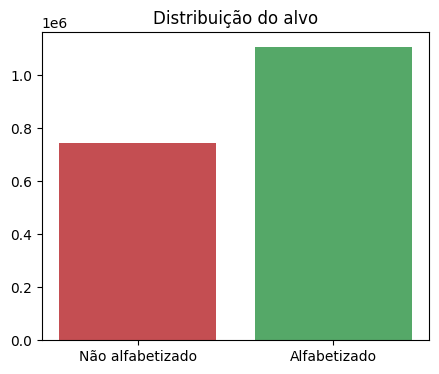

In [2]:
contagem = df["alfabetizado"].value_counts()
print(contagem)
print(f"\nTaxa de alfabetizados: {df['alfabetizado'].mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(5,4))
ax.bar(["Não alfabetizado", "Alfabetizado"], [contagem[False], contagem[True]], color=["#C44E52","#55A868"])
ax.set_title("Distribuição do alvo")
plt.show()

Alvo razoavelmente balanceado (~60/40) — não precisa de reamostragem
agressiva (SMOTE etc.), `class_weight="balanced"` no classificador já é
suficiente, evita complexidade desnecessária no pipeline.

## 2. Valores ausentes nas features

In [3]:
nulos = (df[TODAS_NUMERICAS + TODAS_CATEGORICAS].isna().mean() * 100).round(2).sort_values(ascending=False)
nulos[nulos > 0]

idhm_longevidade          1.89
idhm_educacao             1.89
idhm                      1.89
idhm_renda                1.89
gap_indicador_nacional    1.86
taxa_alfabetizacao        1.86
indicador_nacional        1.86
faixa_risco               1.86
sigla_uf                  1.86
nome_regiao               1.86
dtype: float64

~1,9% de nulos em todas as features municipais — municípios sem
correspondência exata na Gold do ano anterior (fusões/criação de
município, ou o diretório não bate 100% com a tabela de indicador para
aquele caso específico). Baixo o suficiente para imputação simples
(mediana/constante) sem distorcer a distribuição.

## 3. Correlação entre features numéricas e o alvo

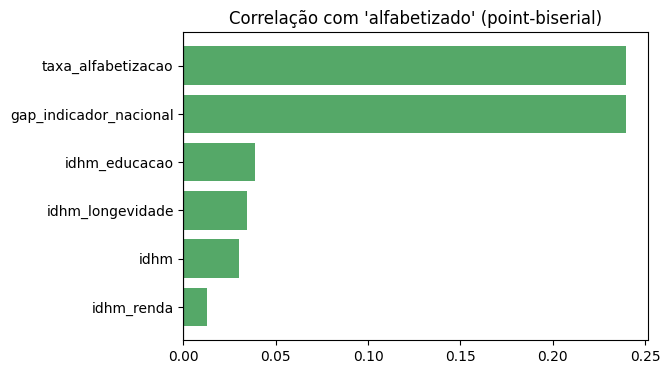

In [4]:
corr = df[TODAS_NUMERICAS + ["alfabetizado"]].astype(float).corr()["alfabetizado"].drop("alfabetizado").sort_values()

fig, ax = plt.subplots(figsize=(6,4))
cores = ["#C44E52" if v < 0 else "#55A868" for v in corr.values]
ax.barh(corr.index, corr.values, color=cores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlação com 'alfabetizado' (point-biserial)")
plt.show()

`taxa_alfabetizacao` (indicador municipal do ano anterior) é a variável
mais correlacionada com o resultado do aluno — esperado, é o retrato mais
direto de como aquele município historicamente performa. Os componentes
de IDHM têm correlação bem mais fraca: desenvolvimento humano municipal
captura algo real, mas está bem mais distante causalmente do resultado
individual do que o próprio histórico educacional do município.

## 4. Taxa de alfabetização por categoria

In [5]:
for col in ["faixa_risco", "rede_label", "nome_regiao"]:
    taxa = df.groupby(col, observed=True)["alfabetizado"].agg(["mean", "count"])
    taxa["mean"] = (taxa["mean"] * 100).round(1)
    print(f"\n--- {col} ---")
    print(taxa.sort_values("mean", ascending=False))


--- faixa_risco ---
                       mean   count
faixa_risco                        
Meta próxima/atingida  90.9   50557
Adequado               74.7  282439
Atenção                62.1  849663
Crítico                47.7  634811

--- rede_label ---
            mean    count
rede_label               
Privada     66.7       24
Estadual    62.5   241074
Municipal   59.4  1610754

--- nome_regiao ---
              mean   count
nome_regiao               
Centro-Oeste  65.5  153094
Sudeste       62.3  742713
Sul           61.0  278290
Nordeste      56.9  465488
Norte         50.7  177885


`faixa_risco` (derivada do próprio indicador municipal) mostra o
gradiente mais claro, como esperado — é quase uma versão categórica da
`taxa_alfabetizacao`. Entre redes, Municipal e Estadual têm taxas
parecidas; Privada tem amostra pequena demais (poucas dezenas de alunos
nesta base, que é majoritariamente de rede pública) para conclusão
confiável — ver limitações no README.

## Conclusões para a modelagem

- Alvo balanceado o bastante para não precisar de reamostragem.
- `taxa_alfabetizacao` e `faixa_risco` (ambas do contexto municipal
  defasado) carregam o sinal mais forte disponível nos dados — reforça a
  hipótese de que o resultado individual do aluno está fortemente
  associado ao histórico do seu município, mais do que ao IDHM isolado.
- Nulos são raros e tratáveis via imputação simples dentro do próprio
  pipeline scikit-learn (não precisa de tratamento manual aqui).
- Ver `notebooks/05_resultados_modelo.ipynb` para o modelo treinado e a
  confirmação (ou não) dessas hipóteses via feature importance/SHAP.